# Kubaho — Model Notebook (initial version)

**Kubaho: a camera-free WiFi-sensing system for elderly fall and wellness monitoring in rural Rwandan homes,
using π RuView and a LoRA-adapted fall-detection model.**
BSc Software Engineering

This notebook covers the ML part of the MVP:

1. **Data engineering**: the CSI quality phase (packet-loss repair, phase sanitisation, Hampel filter,
   band-pass, windowing, session filtering).
2. **Data visualisation**: class distribution, CSI heatmaps, motion profiles, feature distributions and
   correlations, and the domain gap.
3. **Model architecture**: RuView-style CSI encoder + LoRA adapter (layers, activations, optimiser, parameter budget).
4. **Initial performance metrics**: models M0–M7 from proposal Table 5 on leave-one-layout-out splits with
   unseen subjects. Accuracy, precision, recall, F1, sensitivity and specificity, plus McNemar's test.
5. **Deployment artefact**: merged INT8 ONNX model + model card, served by the FastAPI `/predict` endpoint.

> **Data status: these results are preliminary.** The Kubaho-Lab recordings (20 volunteers in a mock rural
> room) and the pilot field data have not been collected yet. Every result below comes from a
> **physics-inspired synthetic CSI generator** (`src/kubaho/synthetic.py`). It reproduces the structure of
> the planned dataset: 12 activities, 2 room layouts, 20 subjects, ESP32-S3 noise, packet loss and phase
> offsets. The RuView pretrained encoder is replaced by a stand-in encoder pre-trained on synthetic
> *generic-room* data. The pipeline is complete and runs end to end; once the real data exists, it replaces
> the synthetic data through `kubaho.data`.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")   # local file store (./mlruns); no tracking server needed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import torch
import mlflow

from kubaho import CLASSES, FLOOR_LEVEL
from kubaho.data import load_or_build
from kubaho.synthetic import (KUBAHO_ACTIVITIES, SOURCE_CLASSES, make_layout, make_subject, simulate_clip, SUB_IDX)
from kubaho.preprocess import (MAX_LOSS, FS, TARGET_FS, interpolate_lost, sanitize_phase, hampel, bandpass,
                               preprocess_window, motion_energy)
from kubaho.features import extract_features, FEATURE_NAMES
from kubaho.baselines import ThresholdDetector, threshold_scores
from kubaho.models import CSIClassifier, CNNLSTM, count_parameters
from kubaho.train import TrainConfig, fit, predict_proba, set_seed
from kubaho.metrics import evaluate, calibrate_threshold, fall_metrics, mcnemar, FALL

SEED = 42
set_seed(SEED)
torch.set_num_threads(os.cpu_count())
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
mlflow.set_tracking_uri((ROOT / "mlruns").as_uri())
mlflow.set_experiment("kubaho")
print("torch", torch.__version__, "| CPU threads", torch.get_num_threads())

2026/11/09 23:45:33 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\HP\kubaho\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


torch 2.15.0+cpu | CPU threads 4


In [2]:
# Chart style: one recessive grid, thin marks, fixed categorical order (blue, orange, aqua).
BLUE, ORANGE, AQUA, RED, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#898781"
INK, INK2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
GROUP_COLORS = {"Floor-level daily activity": BLUE, "Fall": ORANGE, "Other (walk, empty)": AQUA}
SEQ = mcolors.LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV = mcolors.LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a99", "#b8302f"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK2,
    "ytick.color": INK2, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110,
})

def group_of(cls):
    return "Fall" if cls == "fall" else ("Floor-level daily activity" if cls in FLOOR_LEVEL else "Other (walk, empty)")

def save(name):
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")

## 1. Data definition and acquisition

| Source | Content | Volume | Status in this notebook |
|---|---|---|---|
| **Kubaho-Lab** (primary) | CSI from ESP32-S3 at 100 packets/s in a mock rural room (mats, low stools, low bed), 2 layouts; 4 fall types, 6 fall-like/daily activities, walk, empty room | 20 volunteers × 12 activities × 2 layouts × 5 reps = 2,400 events | **Synthetic stand-in** |
| Kubaho-Field | On-device event logs and short CSI windows from 8 pilot homes, caregiver/CHW diary as ground truth | 8 homes × 6 weeks | The API records acknowledgements as ground truth |
| MM-Fi (public) | WiFi CSI for 27 daily actions, 40 subjects | — | Replaced by a synthetic *generic-room* source domain for pre-training |
| RuView pretrained encoder | 128-d CSI embedding model | — | Replaced by a stand-in encoder with the same 128-d interface, pre-trained here |

Each event is a 3 s clip at 100 packets/s. Three raw 2 s windows (offsets 0, 0.5 and 1.0 s) are cut from it and
cleaned. The 0.5 s window is used for validation and testing; all three are used as training augmentation.

In [3]:
t0 = time.time()
X_lab, meta = load_or_build("kubaho_lab")      # (N, 3 crops, 100 frames @ 50 Hz, 52 subcarriers)
X_src, meta_src = load_or_build("source")
print(f"built/loaded in {time.time()-t0:.0f}s")
print("Kubaho-Lab:", X_lab.shape, "| generic-room source:", X_src.shape)
meta.head()

built/loaded in 40s
Kubaho-Lab: (2400, 3, 100, 52) | generic-room source: (1728, 3, 100, 52)


,subject,layout,session,activity,label,class_name,rep,packet_loss
0,1,A,S01-A,fall_forward,0,fall,0,0.016667
1,1,A,S01-A,fall_forward,0,fall,1,0.023333
2,1,A,S01-A,fall_forward,0,fall,2,0.013333
3,1,A,S01-A,fall_forward,0,fall,3,0.043333
4,1,A,S01-A,fall_forward,0,fall,4,0.023333


## 2. Data engineering: the CSI quality phase

The ESP32-S3 delivers complex CSI per packet. Before learning, we:

1. **Repair lost packets**: linear interpolation along time.
2. **Sanitise phase**: unwrap across subcarriers and remove the per-packet linear slope (sampling-time
   offset) and constant (carrier-frequency offset).
3. **Hampel filter**: replace outliers that are more than 3 robust standard deviations from the rolling median.
4. **Band-pass 0.2–20 Hz**: remove the static room response and high-frequency noise. Human motion is
   below 20 Hz, so we then decimate to 50 Hz.
5. **Window**: 2 s windows with a 0.25 s stride on streams (the node), 3 crops per clip for training.
6. **Drop sessions** with more than 10% packet loss.

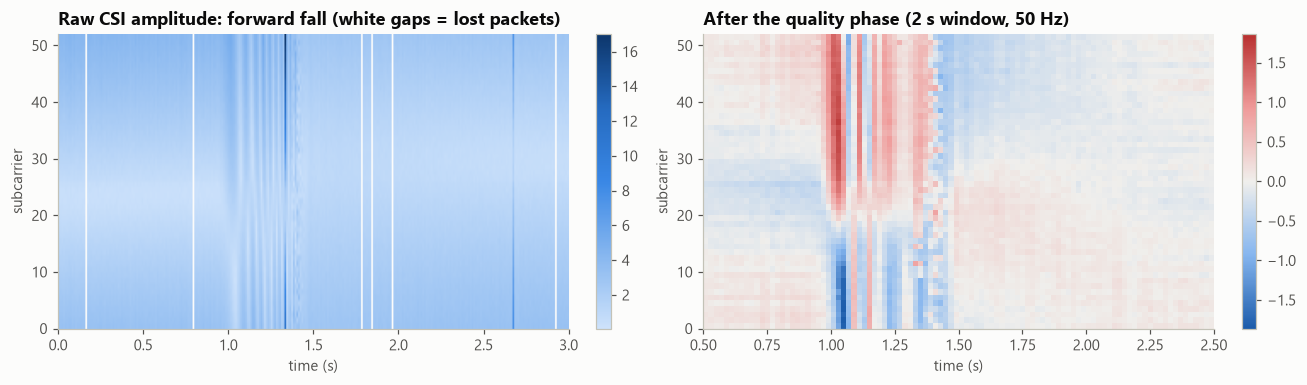

In [4]:
rng = np.random.default_rng(11)
demo_layout, demo_subject = make_layout("A", 8, rural=True), make_subject(rng)
raw = simulate_clip("fall_forward", demo_layout, demo_subject, rng, loss_rate=0.04)
raw_amp = np.abs(raw)
clean = preprocess_window(raw[50:250])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
im = axes[0].imshow(raw_amp.T, aspect="auto", origin="lower", cmap=SEQ, extent=[0, 3, 0, 52])
axes[0].set(title="Raw CSI amplitude: forward fall (white gaps = lost packets)", xlabel="time (s)", ylabel="subcarrier")
axes[0].grid(False); fig.colorbar(im, ax=axes[0], fraction=0.03)
lim = np.abs(clean).max()
im = axes[1].imshow(clean.T, aspect="auto", origin="lower", cmap=DIV, vmin=-lim, vmax=lim, extent=[0.5, 2.5, 0, 52])
axes[1].set(title="After the quality phase (2 s window, 50 Hz)", xlabel="time (s)", ylabel="subcarrier")
axes[1].grid(False); fig.colorbar(im, ax=axes[1], fraction=0.03)
plt.tight_layout(); save("01_raw_vs_clean_heatmap"); plt.show()

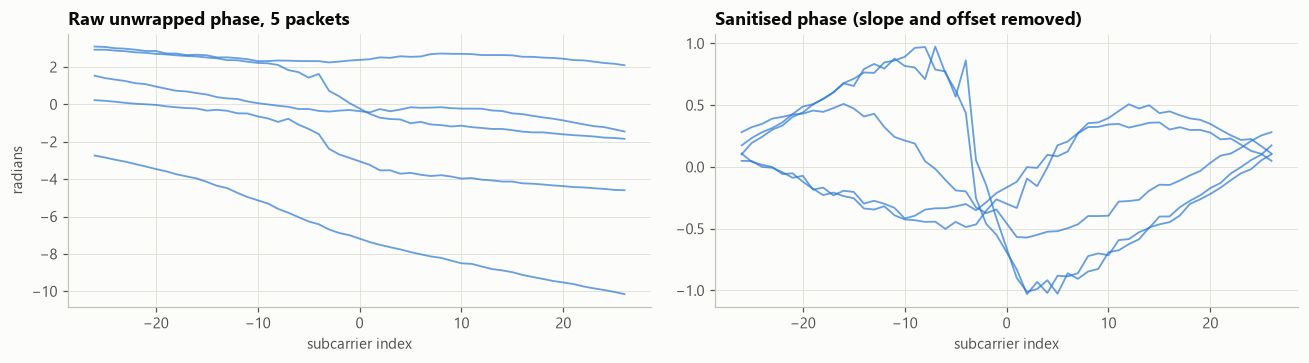

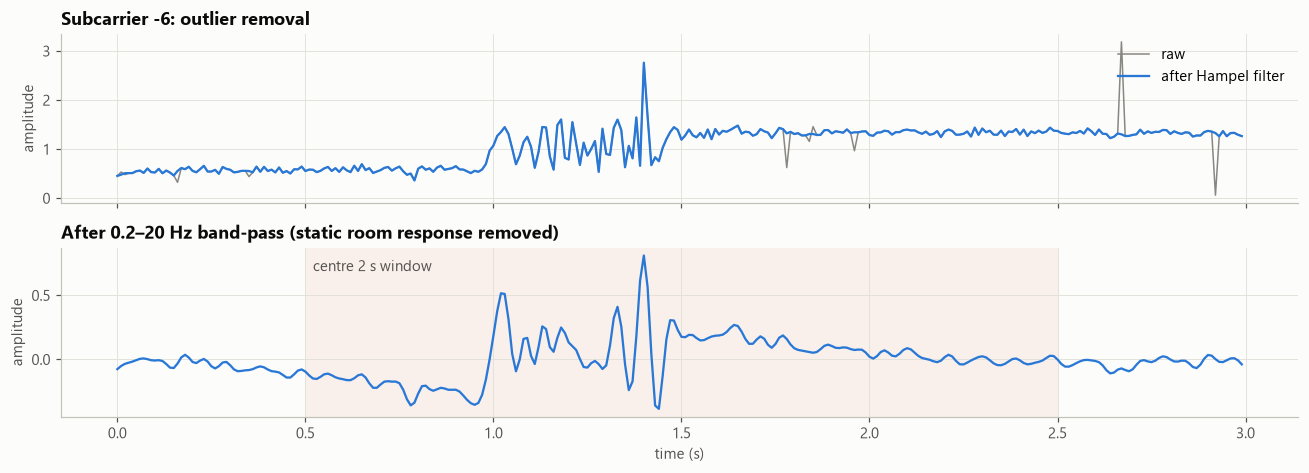

In [5]:
filled = interpolate_lost(raw)
packets = [10, 60, 110, 160, 210]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharex=True)
for p in packets:
    axes[0].plot(SUB_IDX, np.unwrap(np.angle(filled[p])), color=BLUE, lw=1.2, alpha=0.7)
    axes[1].plot(SUB_IDX, sanitize_phase(filled[p:p+1])[0], color=BLUE, lw=1.2, alpha=0.7)
axes[0].set(title="Raw unwrapped phase, 5 packets", xlabel="subcarrier index", ylabel="radians")
axes[1].set(title="Sanitised phase (slope and offset removed)", xlabel="subcarrier index")
plt.tight_layout(); save("02_phase_sanitisation"); plt.show()

k = 20
amp = np.abs(filled)[:, k]
t = np.arange(len(amp)) / FS
h = hampel(np.abs(filled))[:, k]
bp = bandpass(hampel(np.abs(filled)))[:, k]
fig, axes = plt.subplots(2, 1, figsize=(12, 4.4), sharex=True)
axes[0].plot(t, amp, color=GRAY, lw=1, label="raw")
axes[0].plot(t, h, color=BLUE, lw=1.5, label="after Hampel filter")
axes[0].set(title=f"Subcarrier {SUB_IDX[k]}: outlier removal", ylabel="amplitude"); axes[0].legend(loc="upper right")
axes[1].plot(t, bp, color=BLUE, lw=1.5)
axes[1].axvspan(0.5, 2.5, color=ORANGE, alpha=0.08, lw=0)
axes[1].text(0.52, bp.max()*0.85, "centre 2 s window", color=INK2)
axes[1].set(title="After 0.2–20 Hz band-pass (static room response removed)", xlabel="time (s)", ylabel="amplitude")
plt.tight_layout(); save("03_hampel_bandpass"); plt.show()

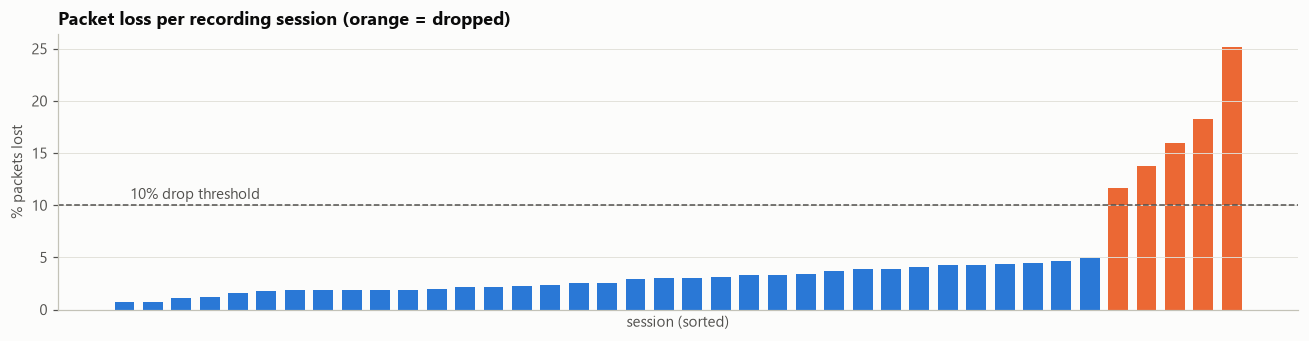

dropped 5 sessions ['S03-B', 'S18-A', 'S10-A', 'S20-A', 'S17-B'] -> 2100 events remain


In [6]:
loss = meta.groupby("session")["packet_loss"].mean().sort_values()
bad = loss[loss > MAX_LOSS].index.tolist()
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.bar(range(len(loss)), loss.values * 100, color=[ORANGE if s in bad else BLUE for s in loss.index], width=0.7)
ax.axhline(MAX_LOSS * 100, color=INK2, lw=1, ls="--"); ax.text(0.2, MAX_LOSS * 100 + 0.6, "10% drop threshold", color=INK2)
ax.set(title="Packet loss per recording session (orange = dropped)", ylabel="% packets lost", xlabel="session (sorted)")
ax.set_xticks([]); plt.tight_layout(); save("04_packet_loss"); plt.show()

keep = ~meta.session.isin(bad)
X_lab, meta = X_lab[keep.values], meta[keep].reset_index(drop=True)
y_lab = meta.label.values
print(f"dropped {len(bad)} sessions {bad} -> {len(meta)} events remain")

## 3. Data visualisation

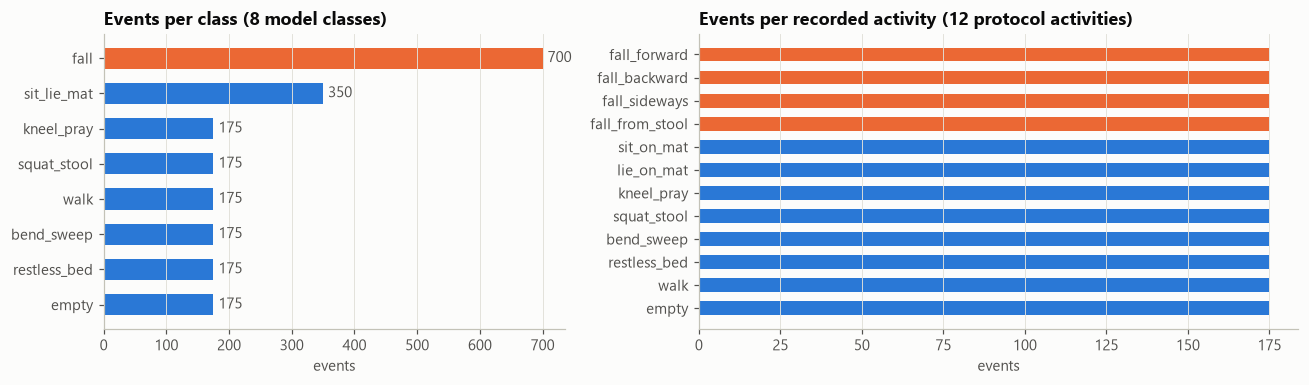

Imbalance: falls are 33% of events; handled with class-weighted focal loss.


In [7]:
counts = meta.class_name.value_counts().reindex(CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].barh(CLASSES[::-1], counts.values[::-1], color=[ORANGE if c == "fall" else BLUE for c in CLASSES[::-1]], height=0.6)
for i, v in enumerate(counts.values[::-1]):
    axes[0].text(v + 8, i, str(v), va="center", color=INK2)
axes[0].set(title="Events per class (8 model classes)", xlabel="events"); axes[0].grid(axis="y", visible=False)
act = meta.activity.value_counts().reindex(list(KUBAHO_ACTIVITIES))
axes[1].barh(act.index[::-1], act.values[::-1], color=[ORANGE if a.startswith("fall") else BLUE for a in act.index[::-1]], height=0.6)
axes[1].set(title="Events per recorded activity (12 protocol activities)", xlabel="events"); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); save("05_class_distribution"); plt.show()
print(f"Imbalance: falls are {counts['fall']/counts.sum():.0%} of events; handled with class-weighted focal loss.")

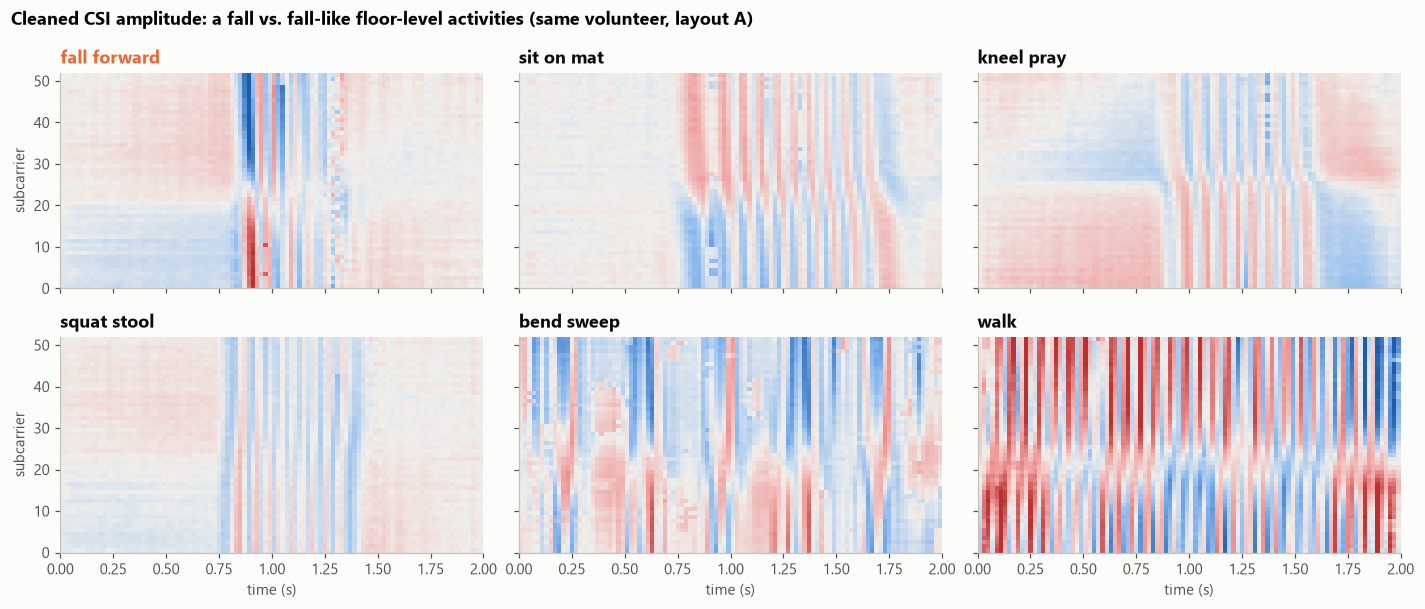

In [8]:
examples = ["fall_forward", "sit_on_mat", "kneel_pray", "squat_stool", "bend_sweep", "walk"]
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6), sharex=True, sharey=True)
wins = [X_lab[meta.index[(meta.subject == 3) & (meta.layout == "A") & (meta.rep == 0) & (meta.activity == a)][0], 1] for a in examples]
lim = np.percentile(np.abs(np.stack(wins)), 99.5)
for ax, a, w in zip(axes.flat, examples, wins):
    ax.imshow(w.T, aspect="auto", origin="lower", cmap=DIV, vmin=-lim, vmax=lim, extent=[0, 2, 0, 52])
    ax.set_title(a.replace("_", " "), color=ORANGE if a.startswith("fall") else INK); ax.grid(False)
for ax in axes[1]: ax.set_xlabel("time (s)")
for ax in axes[:, 0]: ax.set_ylabel("subcarrier")
fig.suptitle("Cleaned CSI amplitude: a fall vs. fall-like floor-level activities (same volunteer, layout A)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); save("06_csi_heatmaps"); plt.show()

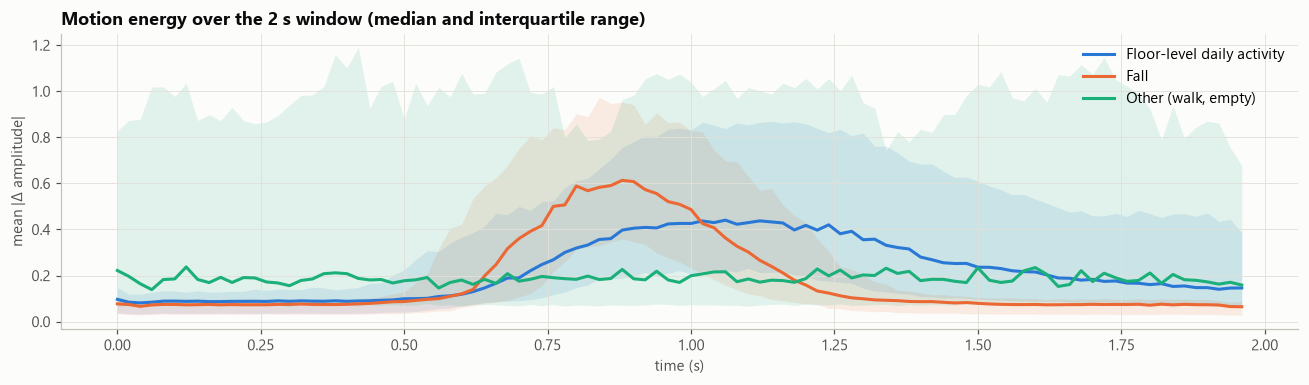

In [9]:
E = motion_energy(X_lab[:, 1])                      # (N, 99)
tt = np.arange(E.shape[1]) / TARGET_FS
groups = meta.class_name.map(group_of)
fig, ax = plt.subplots(figsize=(12, 3.6))
for g, color in GROUP_COLORS.items():
    e = E[(groups == g).values]
    ax.plot(tt, np.median(e, 0), color=color, lw=2, label=g)
    ax.fill_between(tt, *np.percentile(e, [25, 75], 0), color=color, alpha=0.12, lw=0)
ax.set(title="Motion energy over the 2 s window (median and interquartile range)", xlabel="time (s)", ylabel="mean |Δ amplitude|")
ax.legend(loc="upper right"); plt.tight_layout(); save("07_motion_energy_profiles"); plt.show()

23 features for 2100 windows in 18s


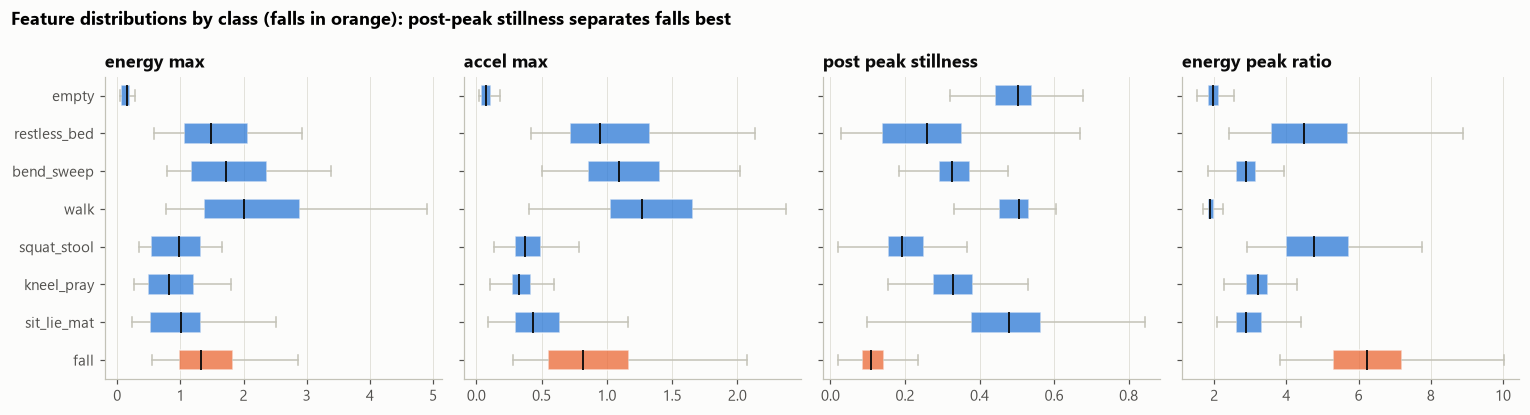

In [10]:
t0 = time.time()
F_lab = extract_features(X_lab[:, 1])
F_df = pd.DataFrame(F_lab, columns=FEATURE_NAMES)
print(f"{F_lab.shape[1]} features for {len(F_lab)} windows in {time.time()-t0:.0f}s")

show = ["energy_max", "accel_max", "post_peak_stillness", "energy_peak_ratio"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, f in zip(axes, show):
    data = [F_df.loc[meta.class_name == c, f].values for c in CLASSES]
    bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS))
    for patch, c in zip(bp["boxes"], CLASSES):
        patch.set(facecolor=ORANGE if c == "fall" else BLUE, alpha=0.75, edgecolor="#fcfcfb")
    ax.set_title(f.replace("_", " ")); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(1, len(CLASSES) + 1), CLASSES)
fig.suptitle("Feature distributions by class (falls in orange): post-peak stillness separates falls best", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); save("08_feature_distributions"); plt.show()

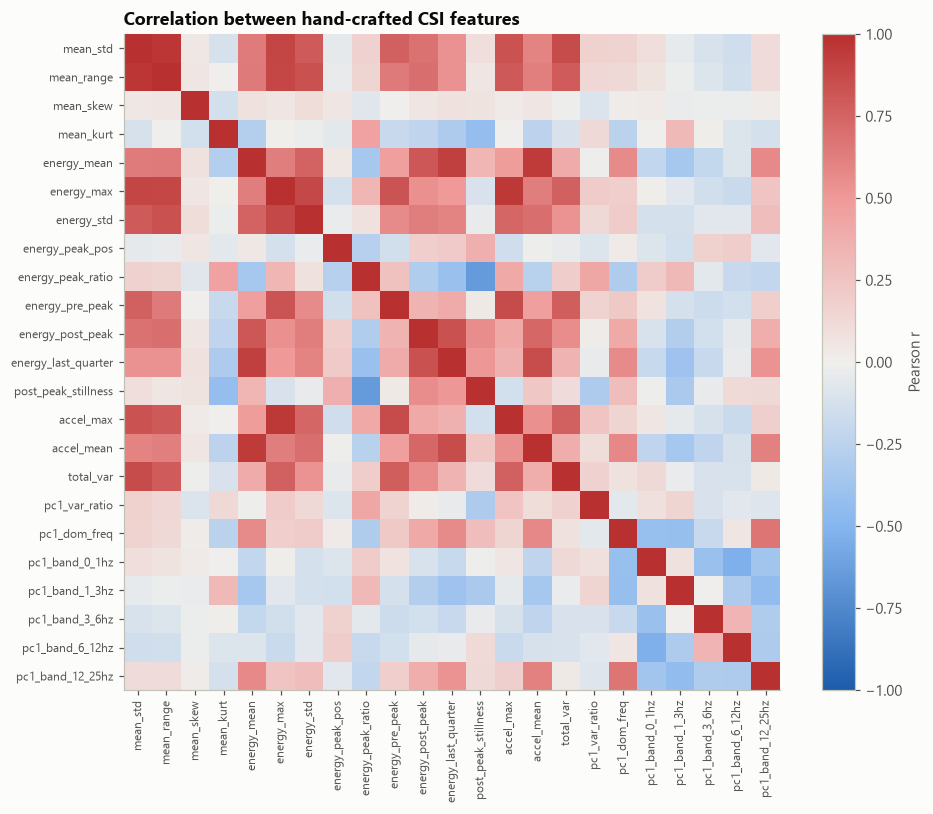

Most correlated pairs (candidates for pruning):
mean_std     mean_range             0.97
energy_max   accel_max              0.95
energy_mean  accel_mean             0.94
             energy_last_quarter    0.92
mean_std     energy_max             0.90


In [11]:
corr = F_df.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.grid(False); fig.colorbar(im, ax=ax, fraction=0.04, label="Pearson r")
ax.set_title("Correlation between hand-crafted CSI features")
plt.tight_layout(); save("09_feature_correlation"); plt.show()
top = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().abs().sort_values(ascending=False).head(5)
print("Most correlated pairs (candidates for pruning):"); print(top.round(2).to_string())

### The domain gap (RQ1)

A generic detector learns that *"a big, sudden change followed by stillness"* means a fall. Its threshold is
calibrated on generic rooms with hard floors and chairs. In a rural room, falls land on mats and are softer,
while squatting onto a low stool or kneeling to pray are fast descents that end in stillness. The plot shows
the threshold detector's two decision variables on the Kubaho-Lab data. The dashed lines are the
thresholds calibrated on generic-room data.

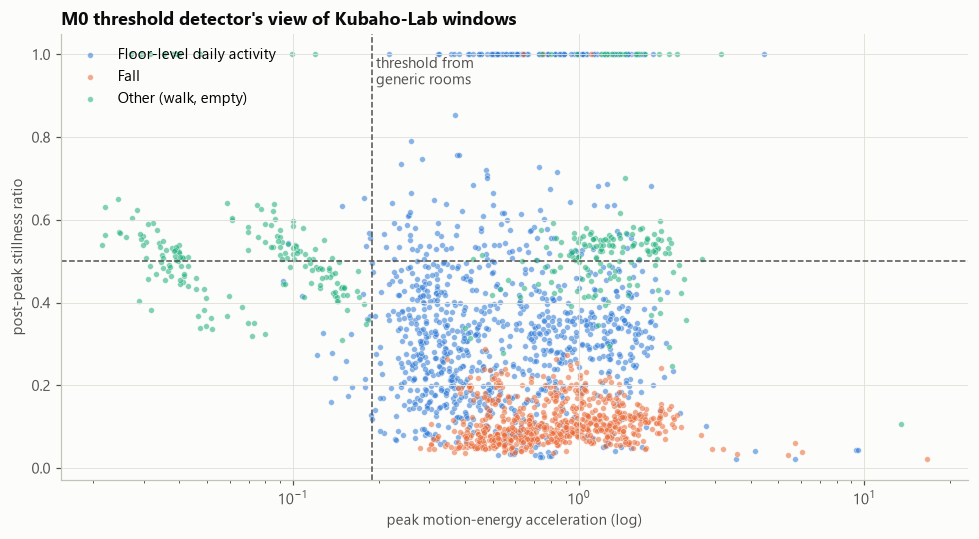

M0 alert fires on 100% of falls and on 78% of floor-level daily activities


In [12]:
src_fall = (meta_src.class_name == "fall").values
m0 = ThresholdDetector().fit(X_src[:, 1], src_fall, target_sensitivity=0.95)
peak, still = threshold_scores(X_lab[:, 1])
fig, ax = plt.subplots(figsize=(9, 5))
for g, color in GROUP_COLORS.items():
    m = (groups == g).values
    ax.scatter(peak[m], still[m], s=14, color=color, alpha=0.55, label=g, edgecolors="#fcfcfb", linewidths=0.4)
ax.axvline(m0.accel_threshold, color=INK2, ls="--", lw=1); ax.axhline(m0.stillness_ratio, color=INK2, ls="--", lw=1)
ax.text(m0.accel_threshold * 1.03, ax.get_ylim()[1] * 0.95, "threshold from\ngeneric rooms", color=INK2, va="top")
ax.set_xscale("log")
ax.set(title="M0 threshold detector's view of Kubaho-Lab windows", xlabel="peak motion-energy acceleration (log)",
       ylabel="post-peak stillness ratio")
ax.legend(loc="upper left"); plt.tight_layout(); save("10_domain_gap_threshold"); plt.show()
alerts = m0.predict(X_lab[:, 1])
print(f"M0 alert fires on {alerts[y_lab == FALL].mean():.0%} of falls and on "
      f"{alerts[np.isin(y_lab, [CLASSES.index(c) for c in FLOOR_LEVEL])].mean():.0%} of floor-level daily activities")

## 4. Evaluation protocol

**Leave-one-layout-out with unseen subjects.** For each fold, the model trains on one room layout
(subjects 1–13), validates on subjects 14–16 in the same layout (early stopping and threshold calibration),
and is **tested on the other layout with subjects 17–20**. The test room and test people are both unseen.
There are two folds (A→B, B→A), and the reported metrics are their mean.

The fall-alert threshold is calibrated on the validation set: the highest threshold that keeps sensitivity
at or above 95%, which gives the fewest false alarms.

In [13]:
def split(train_layout):
    test_layout = "B" if train_layout == "A" else "A"
    tr = np.where((meta.layout == train_layout) & (meta.subject <= 13))[0]
    va = np.where((meta.layout == train_layout) & meta.subject.between(14, 16))[0]
    te = np.where((meta.layout == test_layout) & (meta.subject >= 17))[0]
    return tr, va, te

for L in "AB":
    tr, va, te = split(L)
    print(f"fold {L}->{'B' if L=='A' else 'A'}: train {len(tr)} events ({len(tr)*3} windows), val {len(va)}, test {len(te)}"
          f" (falls in test: {(y_lab[te]==FALL).sum()})")

fold A->B: train 720 events (2160 windows), val 180, test 180 (falls in test: 60)
fold B->A: train 720 events (2160 windows), val 180, test 120 (falls in test: 40)


## 5. Pre-trained CSI encoder (RuView-encoder stand-in)

RuView ships a pretrained 128-d CSI encoder. We pre-train an encoder with the same interface on
**generic-room data** only (6 activities, 3 office layouts, hard floors, chairs). It has never seen mats,
low stools or floor-level postures. This reproduces the starting point the proposal assumes.

In [14]:
y_src = meta_src.label.values
s_tr, s_va = np.where(meta_src.subject < 24)[0], np.where(meta_src.subject >= 24)[0]
encoder_model = CSIClassifier(n_classes=len(SOURCE_CLASSES))
flat = X_src[s_tr].reshape(-1, 52)
encoder_model.encoder.set_normalization(flat.mean(0), flat.std(0))
hist = fit(encoder_model, X_src[s_tr], y_src[s_tr], X_src[s_va], y_src[s_va], len(SOURCE_CLASSES),
           TrainConfig(epochs=20, lr=1e-3, seed=SEED), run_name="pretrain_encoder")
ENCODER_PATH = MODELS / "ruview_encoder_standin.pt"
torch.save(encoder_model.encoder.state_dict(), ENCODER_PATH)
print(f"source-domain val macro-F1 {hist['best_val_macro_f1']:.3f} after {hist['epochs_run']} epochs ({hist['seconds']:.0f}s)")

source-domain val macro-F1 0.854 after 20 epochs (81s)


## 6. Model architecture

```
CSI window (100 frames × 52 subcarriers, 50 Hz)
 └─ normalisation (per-subcarrier mean/std, stored in the model)
 └─ Conv1d 52→96, k=5, stride 2 + GELU
 └─ Conv1d 96→96, k=3, stride 2 + GELU        (temporal downsampling: 100 frames → 25 tokens)
 └─ + learned positional embedding (25 × 96)
 └─ 3 × pre-norm Transformer block
 │     LayerNorm → multi-head self-attention (4 heads; q, k, v, o Linear 96→96)  ← LoRA on q and v
 │     LayerNorm → FFN Linear 96→192 → GELU → Linear 192→96
 │     residual connections, dropout 0.1
 └─ LayerNorm → mean pooling → Linear 96→128 → 128-d embedding   (frozen RuView-style encoder)
 └─ classification head Linear 128→8 (trainable)
```

The stand-in encoder is deliberately small (~0.3 M parameters) so that the full benchmark trains on a
2-core laptop CPU. RuView's encoder takes its place when the weights are available.

**LoRA.** For each adapted weight $W \in \mathbb{R}^{d\times k}$ (frozen), we learn $\Delta W = BA$ with
$B\in\mathbb{R}^{d\times r}$, $A\in\mathbb{R}^{r\times k}$, $r \ll \min(d,k)$, scaled by $\alpha/r$ ($\alpha = 2r$).
$B$ starts at zero, so training begins exactly at the pretrained model.

**Training.** Class-weighted focal loss ($\gamma = 2$) for class imbalance, AdamW (weight decay 0.01), cosine
learning-rate schedule, early stopping on validation macro-F1 (patience 6), random-crop augmentation.
Experiments are logged to MLflow (`mlruns/`).

In [15]:
from peft import LoraConfig, get_peft_model

def pretrained_classifier():
    m = CSIClassifier(n_classes=len(CLASSES))
    m.encoder.load_state_dict(torch.load(ENCODER_PATH))
    return m

def lora_model(r):
    cfg = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05, target_modules=["q", "v"], modules_to_save=["head"])
    return get_peft_model(pretrained_classifier(), cfg)

def lora_param_count(m):
    return sum(p.numel() for n, p in m.named_parameters() if "lora_" in n)

print(pretrained_classifier())
enc_params = count_parameters(pretrained_classifier().encoder)
rows = []
for r in (4, 8, 16):
    m = lora_model(r)
    lp = lora_param_count(m)
    trainable = count_parameters(m, trainable_only=True)
    rows.append({"LoRA rank r": r, "LoRA params": lp, "% of encoder": 100 * lp / enc_params,
                 "trainable incl. head": trainable, "adapter size fp32 (KB)": lp * 4 / 1024, "adapter size int8 (KB)": lp / 1024})
print(f"Encoder parameters: {enc_params:,}")
pd.DataFrame(rows).round(2)

CSIClassifier(
  (encoder): CSIEncoder(
    (stem): Sequential(
      (0): Conv1d(52, 96, kernel_size=(5,), stride=(2,), padding=(2,))
      (1): GELU(approximate='none')
      (2): Conv1d(96, 96, kernel_size=(3,), stride=(2,), padding=(1,))
      (3): GELU(approximate='none')
    )
    (blocks): ModuleList(
      (0-2): 3 x Block(
        (ln1): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): Attention(
          (q): Linear(in_features=96, out_features=96, bias=True)
          (k): Linear(in_features=96, out_features=96, bias=True)
          (v): Linear(in_features=96, out_features=96, bias=True)
          (o): Linear(in_features=96, out_features=96, bias=True)
          (drop): Dropout(p=0.1, inplace=False)
        )
        (ln2): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
        (ff1): Linear(in_features=96, out_features=192, bias=True)
        (ff2): Linear(in_features=192, out_features=96, bias=True)
        (drop): Dropout(p

Encoder parameters: 292,160


,LoRA rank r,LoRA params,% of encoder,trainable incl. head,adapter size fp32 (KB),adapter size int8 (KB)
0,4,4608,1.58,5640,18.0,4.5
1,8,9216,3.15,10248,36.0,9.0
2,16,18432,6.31,19464,72.0,18.0


## 7. Training and benchmarking M0–M7 (proposal Table 5)

| ID | Model | Input |
|---|---|---|
| M0 | RuView-style threshold detector (calibrated on generic rooms) | motion-energy acceleration |
| M1 | Random Forest | 23 statistical features |
| M2 | XGBoost | 23 statistical features |
| M3 | SVM (RBF) | 23 statistical features |
| M4 | CNN-LSTM from scratch | cleaned CSI windows |
| M5 | Pretrained encoder + linear probe | 128-d embeddings |
| M6 | Pretrained encoder, full fine-tune | cleaned CSI windows |
| **M7** | **Pretrained encoder + LoRA adapter (r = 4, proposed)** | cleaned CSI windows |

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

t0 = time.time()
F_all = extract_features(X_lab.reshape(-1, *X_lab.shape[2:])).reshape(len(X_lab), 3, -1)  # features for every crop
print(f"features for all crops in {time.time()-t0:.0f}s")

@torch.no_grad()
def embed(model, X, bs=256):
    model.eval()
    return np.concatenate([model.embed(torch.from_numpy(X[i:i+bs])).numpy() for i in range(0, len(X), bs)])

def classical(make):
    def run(tr, va, te):
        clf = make().fit(F_all[tr].reshape(-1, F_all.shape[-1]), np.repeat(y_lab[tr], 3))
        return clf.predict_proba(F_all[va, 1]), clf.predict_proba(F_all[te, 1]), clf
    return run

def torch_model(make, lr, epochs=25, name=None):
    def run(tr, va, te):
        m = make()
        if hasattr(m, "set_normalization"):          # models trained from scratch use target-domain stats
            flat = X_lab[tr].reshape(-1, 52); m.set_normalization(flat.mean(0), flat.std(0))
        h = fit(m, X_lab[tr], y_lab[tr], X_lab[va], y_lab[va], len(CLASSES),
                TrainConfig(epochs=epochs, lr=lr, seed=SEED), run_name=name)
        print(f"   {name}: {h['epochs_run']} epochs, {h['seconds']:.0f}s, val macro-F1 {h['best_val_macro_f1']:.3f}")
        return predict_proba(m, X_lab[va]), predict_proba(m, X_lab[te]), m
    return run

def linear_probe(tr, va, te):
    enc = pretrained_classifier()
    Z = lambda idx, crop: embed(enc, X_lab[idx, crop])
    Ztr = np.concatenate([Z(tr, c) for c in range(3)])
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    clf.fit(Ztr, np.tile(y_lab[tr], 3))
    return clf.predict_proba(Z(va, 1)), clf.predict_proba(Z(te, 1)), clf

MODELS_TO_RUN = {
    "M1 Random Forest": classical(lambda: RandomForestClassifier(400, class_weight="balanced", n_jobs=-1, random_state=SEED)),
    "M2 XGBoost": classical(lambda: XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.9,
                                                  colsample_bytree=0.9, random_state=SEED, n_jobs=-1)),
    "M3 SVM (RBF)": classical(lambda: make_pipeline(StandardScaler(), SVC(C=10, probability=True, class_weight="balanced",
                                                                          random_state=SEED))),
    "M4 CNN-LSTM (scratch)": torch_model(lambda: CNNLSTM(len(CLASSES)), lr=1e-3, name="M4_cnn_lstm"),
    "M5 Encoder + linear probe": linear_probe,
    "M6 Encoder full fine-tune": torch_model(pretrained_classifier, lr=3e-4, name="M6_full_finetune"),
    "M7 Encoder + LoRA r=4 (proposed)": torch_model(lambda: lora_model(4), lr=2e-3, name="M7_lora_r4"),
}

features for all crops in 96s


In [17]:
results, test_store = [], {}
for L in "AB":
    tr, va, te = split(L)
    fold = f"{L}->{'B' if L == 'A' else 'A'}"
    print(f"=== fold {fold}")
    m0_pred = m0.predict(X_lab[te, 1])
    results.append({"model": "M0 Threshold (RuView-style)", "fold": fold, **fall_metrics(y_lab[te], m0_pred)})
    test_store[("M0 Threshold (RuView-style)", fold)] = {"y": y_lab[te], "fall_pred": m0_pred, "idx": te}
    for name, run in MODELS_TO_RUN.items():
        t0 = time.time()
        p_va, p_te, fitted = run(tr, va, te)
        thr = calibrate_threshold(y_lab[va], p_va[:, FALL])
        res = evaluate(y_lab[te], p_te, thr)
        results.append({"model": name, "fold": fold, **res, "train_s": time.time() - t0})
        test_store[(name, fold)] = {"y": y_lab[te], "proba": p_te, "fall_pred": p_te[:, FALL] >= thr, "idx": te,
                                    "model": fitted}
        print(f"  {name:<34} fall F1 {res['fall_f1']:.3f}  sens {res['fall_sensitivity']:.3f}  "
              f"spec(floor) {res['specificity_floor_level']:.3f}  macro-F1 {res['macro_f1']:.3f}")
res_df = pd.DataFrame(results)

=== fold A->B


  M1 Random Forest                   fall F1 0.247  sens 0.150  spec(floor) 0.956  macro-F1 0.194


  M2 XGBoost                         fall F1 0.527  sens 0.400  spec(floor) 0.922  macro-F1 0.330


  M3 SVM (RBF)                       fall F1 0.549  sens 0.467  spec(floor) 0.844  macro-F1 0.317


   M4_cnn_lstm: 25 epochs, 39s, val macro-F1 0.836


  M4 CNN-LSTM (scratch)              fall F1 0.000  sens 0.000  spec(floor) 0.967  macro-F1 0.078


... (8 outputs left out)

  M5 Encoder + linear probe          fall F1 0.686  sens 0.600  spec(floor) 0.900  macro-F1 0.353


   M6_full_finetune: 18 epochs, 42s, val macro-F1 0.865


  M6 Encoder full fine-tune          fall F1 0.737  sens 0.700  spec(floor) 0.867  macro-F1 0.479


   M7_lora_r4: 16 epochs, 33s, val macro-F1 0.727
  M7 Encoder + LoRA r=4 (proposed)   fall F1 0.758  sens 0.900  spec(floor) 0.683  macro-F1 0.438


In [18]:
cols = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "fall_precision", "fall_sensitivity", "fall_f1",
        "specificity_floor_level", "specificity_all_non_fall", "false_alarms"]
order = ["M0 Threshold (RuView-style)"] + list(MODELS_TO_RUN)
summary = res_df.groupby("model")[cols].mean().reindex(order)
summary.to_csv(ROOT / "docs" / "results_summary.csv")
summary.style.format("{:.3f}", subset=cols[:-1]).format("{:.1f}", subset=["false_alarms"]).highlight_max(
    subset=["fall_f1", "macro_f1", "specificity_floor_level"], color="#cde2fb")

,accuracy,macro_precision,macro_recall,macro_f1,fall_precision,fall_sensitivity,fall_f1,specificity_floor_level,specificity_all_non_fall,false_alarms
model,,,,,,,,,,
M0 Threshold (RuView-style),nan,nan,nan,nan,0.442,0.988,0.610,0.231,0.375,62.0
M1 Random Forest,0.206,0.204,0.236,0.166,0.846,0.100,0.171,0.978,0.983,2.0
M2 XGBoost,0.333,0.280,0.338,0.264,0.787,0.300,0.424,0.944,0.958,4.5
M3 SVM (RBF),0.539,0.564,0.506,0.475,0.740,0.558,0.636,0.872,0.904,10.0
M4 CNN-LSTM (scratch),0.267,0.183,0.198,0.146,0.238,0.125,0.164,0.892,0.919,7.0
M5 Encoder + linear probe,0.464,0.382,0.415,0.365,0.812,0.767,0.780,0.883,0.913,9.0
M6 Encoder full fine-tune,0.542,0.507,0.509,0.493,0.796,0.533,0.621,0.906,0.929,6.5
M7 Encoder + LoRA r=4 (proposed),0.493,0.448,0.470,0.421,0.768,0.883,0.816,0.803,0.852,13.0


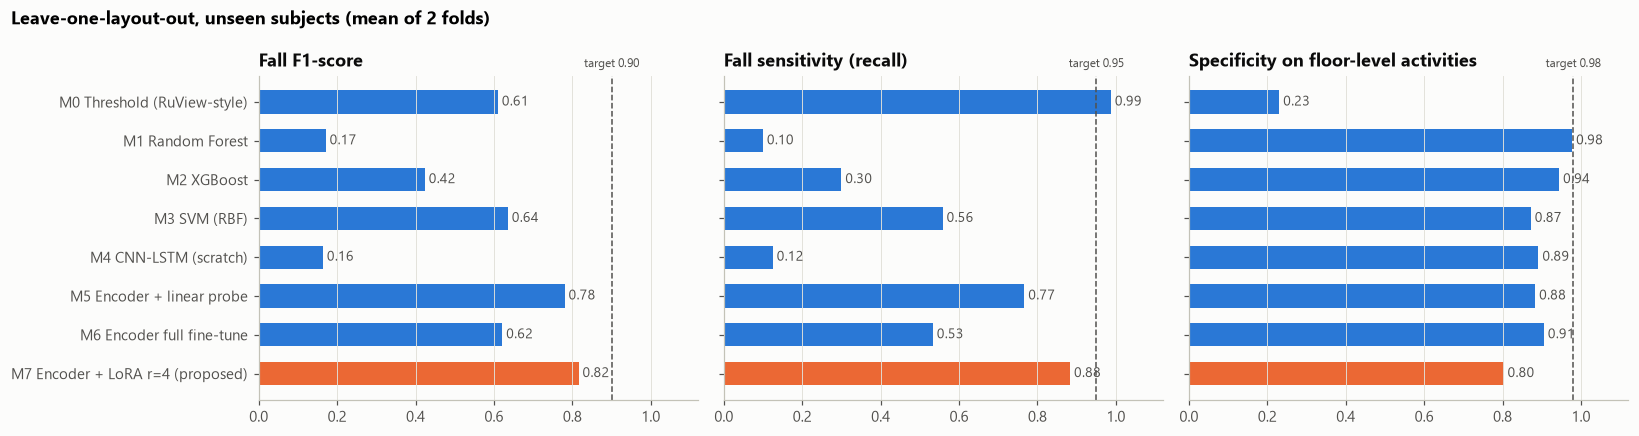

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
names = summary.index.tolist()
for ax, (metric, title) in zip(axes, [("fall_f1", "Fall F1-score"), ("fall_sensitivity", "Fall sensitivity (recall)"),
                                      ("specificity_floor_level", "Specificity on floor-level activities")]):
    vals = summary[metric].values
    ax.barh(range(len(names)), vals, color=[ORANGE if n.startswith("M7") else BLUE for n in names], height=0.6)
    for i, v in enumerate(vals):
        ax.text(min(v, 1) + 0.01, i, f"{v:.2f}", va="center", color=INK2, fontsize=9)
    target = {"fall_f1": 0.90, "fall_sensitivity": 0.95, "specificity_floor_level": 0.98}[metric]
    ax.axvline(target, color=INK2, ls="--", lw=1); ax.text(target, -0.9, f"target {target:.2f}", color=INK2, ha="center", fontsize=8)
    ax.set(title=title, xlim=(0, 1.12)); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(names)), names); axes[0].invert_yaxis()
fig.suptitle("Leave-one-layout-out, unseen subjects (mean of 2 folds)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); save("11_model_comparison"); plt.show()

### LoRA rank sweep (r ∈ {4, 8, 16}, fold A→B)

In [20]:
sweep = []
tr, va, te = split("A")
for r in (4, 8, 16):
    if r == 4:
        row = res_df[(res_df.model.str.startswith("M7")) & (res_df.fold == "A->B")].iloc[0].to_dict()
    else:
        p_va, p_te, _ = torch_model(lambda: lora_model(r), lr=2e-3, name=f"M7_lora_r{r}")(tr, va, te)
        row = evaluate(y_lab[te], p_te, calibrate_threshold(y_lab[va], p_va[:, FALL]))
    sweep.append({"rank": r, "fall_f1": row["fall_f1"], "macro_f1": row["macro_f1"],
                  "specificity_floor_level": row["specificity_floor_level"]})
sweep_df = pd.DataFrame(sweep).set_index("rank")
sweep_df["% of encoder"] = [100 * lora_param_count(lora_model(r)) / enc_params for r in sweep_df.index]
sweep_df.round(3)

   M7_lora_r8: 13 epochs, 25s, val macro-F1 0.764


   M7_lora_r16: 24 epochs, 48s, val macro-F1 0.865


,fall_f1,macro_f1,specificity_floor_level,% of encoder
rank,,,,
4,0.874,0.405,0.922,1.577
8,0.735,0.430,0.978,3.154
16,0.680,0.442,0.933,6.309


## 8. Detailed metrics for the proposed model (M7, both test folds pooled)

              precision    recall  f1-score   support

        fall      0.829     0.680     0.747       100
 sit_lie_mat      0.500     0.040     0.074        50
  kneel_pray      0.000     0.000     0.000        25
 squat_stool      0.125     0.120     0.122        25
        walk      0.786     0.880     0.830        25
  bend_sweep      0.409     0.720     0.522        25
restless_bed      0.106     0.360     0.164        25
       empty      0.889     0.960     0.923        25

    accuracy                          0.487       300
   macro avg      0.455     0.470     0.423       300
weighted avg      0.553     0.487     0.475       300



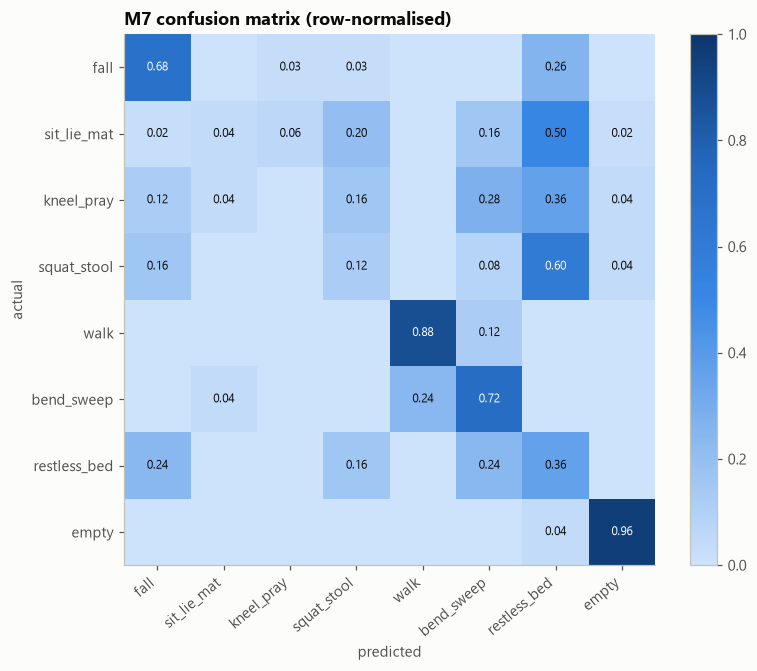

In [21]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve

M7 = "M7 Encoder + LoRA r=4 (proposed)"
y7 = np.concatenate([test_store[(M7, f)]["y"] for f in ("A->B", "B->A")])
p7 = np.concatenate([test_store[(M7, f)]["proba"] for f in ("A->B", "B->A")])
print(classification_report(y7, p7.argmax(1), target_names=CLASSES, digits=3))

cm = confusion_matrix(y7, p7.argmax(1), normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(cm, cmap=SEQ, vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j] >= 0.01:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="#fcfcfb" if cm[i, j] > 0.55 else INK)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=40, ha="right"); ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set(xlabel="predicted", ylabel="actual", title="M7 confusion matrix (row-normalised)"); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04); plt.tight_layout(); save("12_confusion_matrix"); plt.show()

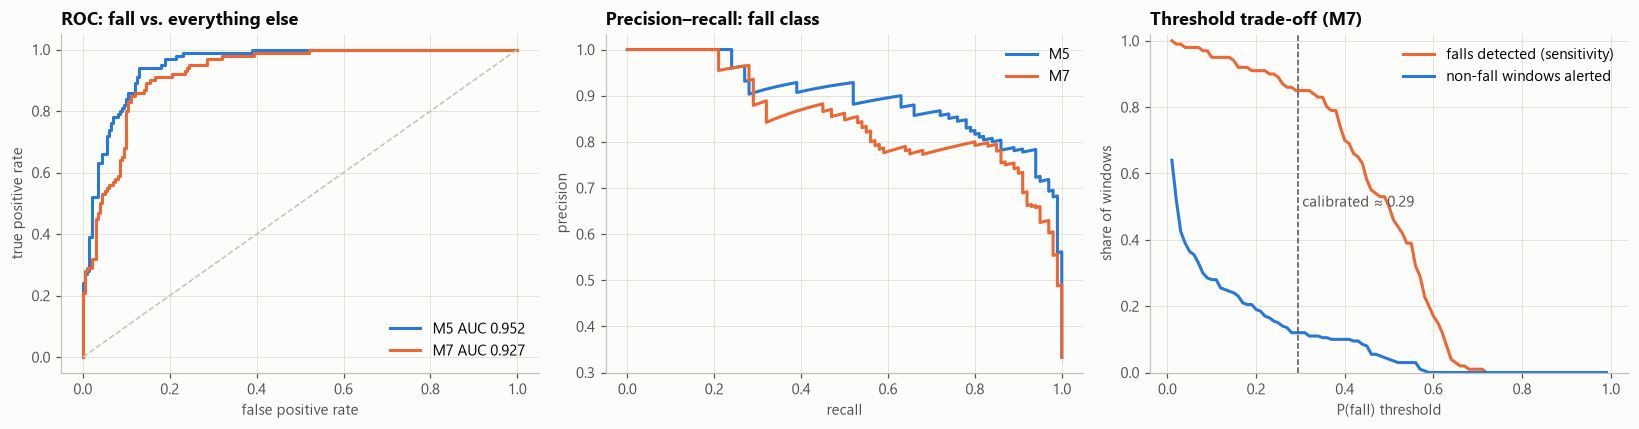

In [22]:
is_fall = y7 == FALL
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, color in [("M5 Encoder + linear probe", BLUE), (M7, ORANGE)]:
    yy = np.concatenate([test_store[(name, f)]["y"] for f in ("A->B", "B->A")]) == FALL
    pp = np.concatenate([test_store[(name, f)]["proba"] for f in ("A->B", "B->A")])[:, FALL]
    fpr, tpr, _ = roc_curve(yy, pp); prec, rec, _ = precision_recall_curve(yy, pp)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name.split(' ')[0]} AUC {auc(fpr, tpr):.3f}")
    axes[1].plot(rec, prec, color=color, lw=2, label=name.split(" ")[0])
axes[0].plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
axes[0].set(title="ROC: fall vs. everything else", xlabel="false positive rate", ylabel="true positive rate"); axes[0].legend()
axes[1].set(title="Precision–recall: fall class", xlabel="recall", ylabel="precision"); axes[1].legend()

thr_grid = np.linspace(0.01, 0.99, 99)
sens = [(p7[is_fall, FALL] >= t).mean() for t in thr_grid]
fa_rate = [(p7[~is_fall, FALL] >= t).mean() for t in thr_grid]
ax = axes[2]
ax.plot(thr_grid, sens, color=ORANGE, lw=2, label="falls detected (sensitivity)")
ax.plot(thr_grid, fa_rate, color=BLUE, lw=2, label="non-fall windows alerted")
ax.set(title="Threshold trade-off (M7)", xlabel="P(fall) threshold", ylabel="share of windows", ylim=(0, 1.02))
thr_used = res_df[res_df.model == M7].threshold.mean()
ax.axvline(thr_used, color=INK2, ls="--", lw=1); ax.text(thr_used + 0.01, 0.5, f"calibrated ≈ {thr_used:.2f}", color=INK2)
ax.legend(loc="upper right")
plt.tight_layout(); save("13_roc_pr_threshold"); plt.show()

### Success criteria (proposal Table 6)

In [23]:
m7 = summary.loc[M7]
lp4 = lora_param_count(lora_model(4))
targets = pd.DataFrame([
    ("Sensitivity (recall) for falls", "≥ 95%", f"{m7.fall_sensitivity:.1%}", m7.fall_sensitivity >= 0.95),
    ("Specificity on floor-level ADLs", "≥ 98%", f"{m7.specificity_floor_level:.1%}", m7.specificity_floor_level >= 0.98),
    ("F1-score (fall class)", "≥ 0.90", f"{m7.fall_f1:.3f}", m7.fall_f1 >= 0.90),
    ("Adapter size", "< 2% of encoder; < 100 KB", f"{100*lp4/enc_params:.2f}%; {lp4*4/1024:.1f} KB fp32", lp4/enc_params < 0.02 and lp4*4/1024 < 100),
    ("F1 gain over generic baselines (H1)", "≥ +15 pp over M0 and M5",
     f"+{100*(m7.fall_f1-summary.loc['M0 Threshold (RuView-style)'].fall_f1):.1f} pp vs M0, "
     f"+{100*(m7.fall_f1-summary.loc['M5 Encoder + linear probe'].fall_f1):.1f} pp vs M5",
     (m7.fall_f1 - max(summary.loc['M0 Threshold (RuView-style)'].fall_f1, summary.loc['M5 Encoder + linear probe'].fall_f1)) >= 0.15),
    ("Within 2 pp of full fine-tune (H1)", "|M7 − M6| ≤ 2 pp", f"{100*(m7.fall_f1-summary.loc['M6 Encoder full fine-tune'].fall_f1):+.1f} pp",
     abs(m7.fall_f1 - summary.loc['M6 Encoder full fine-tune'].fall_f1) <= 0.02),
    ("False alarms per household per week", "≤ 1", "pending pilot", None),
    ("On-device latency (ESP32-S3)", "< 200 ms", "pending hardware (CPU latency in §10)", None),
    ("Fall-to-SMS time", "< 60 s median", "pending pilot (MVP pipeline in API)", None),
], columns=["metric", "target", "result (synthetic data)", "met"])
targets

,metric,target,result (synthetic data),met
0,Sensitivity (recall) for falls,≥ 95%,88.3%,False
1,Specificity on floor-level ADLs,≥ 98%,80.3%,False
2,F1-score (fall class),≥ 0.90,0.816,False
3,Adapter size,< 2% of encoder; < 100 KB,1.58%; 18.0 KB fp32,True
4,F1 gain over generic baselines (H1),≥ +15 pp over M0 and M5,"+20.6 pp vs M0, +3.6 pp vs M5",False
5,Within 2 pp of full fine-tune (H1),|M7 − M6| ≤ 2 pp,+19.5 pp,False
6,False alarms per household per week,≤ 1,pending pilot,None
7,On-device latency (ESP32-S3),< 200 ms,pending hardware (CPU latency in §10),None
8,Fall-to-SMS time,< 60 s median,pending pilot (MVP pipeline in API),None


### McNemar's test (H0: no difference between M7 and the baselines, α = 0.05)

In [24]:
def correct(name):
    return np.concatenate([test_store[(name, f)]["fall_pred"] == (test_store[(name, f)]["y"] == FALL) for f in ("A->B", "B->A")])

rows = []
for other in ["M0 Threshold (RuView-style)", "M5 Encoder + linear probe", "M6 Encoder full fine-tune"]:
    t = mcnemar(correct(M7), correct(other))
    rows.append({"comparison": f"M7 vs {other}", "only M7 correct": t["a_only_correct"],
                 "only other correct": t["b_only_correct"], "p-value": t["p_value"],
                 "significant (α=0.05)": t["p_value"] < 0.05})
pd.DataFrame(rows)

,comparison,only M7 correct,only other correct,p-value,significant (α=0.05)
0,M7 vs M0 Threshold (RuView-style),102,15,4.439258e-17,True
1,M7 vs M5 Encoder + linear probe,20,20,1.000000e+00,False
2,M7 vs M6 Encoder full fine-tune,44,19,2.227532e-03,True


## 9. Error analysis (RQ3): which floor-level activities look like falls?

False-alarm rate per protocol activity (share of test windows that trigger a fall alert), pooled over both folds.

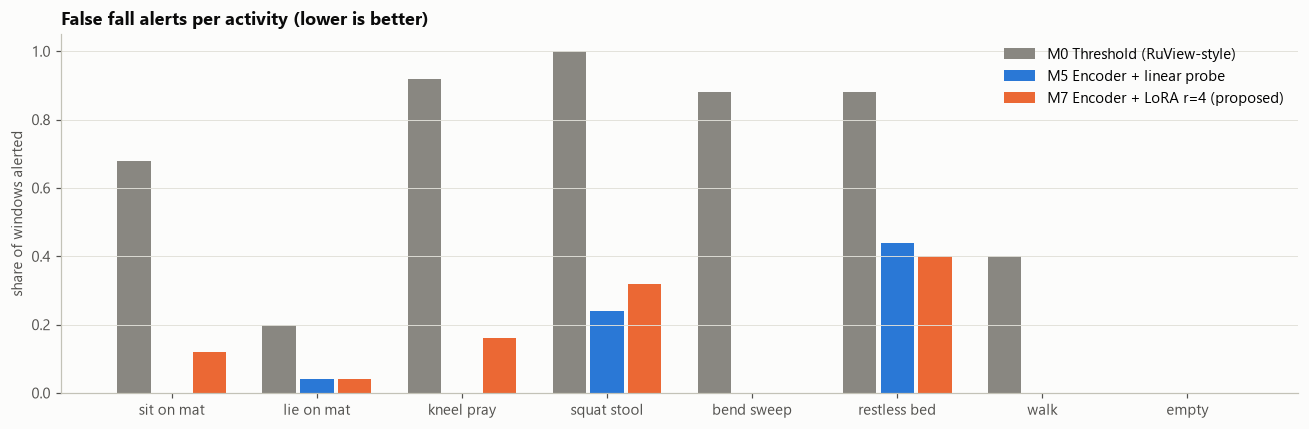

,M0 Threshold (RuView-style),M5 Encoder + linear probe,M7 Encoder + LoRA r=4 (proposed)
sit_on_mat,0.68,0.00,0.12
lie_on_mat,0.20,0.04,0.04
kneel_pray,0.92,0.00,0.16
squat_stool,1.00,0.24,0.32
bend_sweep,0.88,0.00,0.00
restless_bed,0.88,0.44,0.40
walk,0.40,0.00,0.00
empty,0.00,0.00,0.00


In [25]:
acts = [a for a in KUBAHO_ACTIVITIES if not a.startswith("fall")]
cmp_models = [("M0 Threshold (RuView-style)", GRAY), ("M5 Encoder + linear probe", BLUE), (M7, ORANGE)]
rates = {}
for name, _ in cmp_models:
    idx = np.concatenate([test_store[(name, f)]["idx"] for f in ("A->B", "B->A")])
    pred = np.concatenate([test_store[(name, f)]["fall_pred"] for f in ("A->B", "B->A")])
    a = meta.activity.values[idx]
    rates[name] = [pred[a == act].mean() for act in acts]
fig, ax = plt.subplots(figsize=(12, 4))
w = 0.26
for k, (name, color) in enumerate(cmp_models):
    ax.bar(np.arange(len(acts)) + (k - 1) * w, rates[name], width=w - 0.03, color=color, label=name)
ax.set_xticks(range(len(acts)), [a.replace("_", " ") for a in acts])
ax.set(title="False fall alerts per activity (lower is better)", ylabel="share of windows alerted")
ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
plt.tight_layout(); save("14_false_alarms_by_activity"); plt.show()
pd.DataFrame(rates, index=acts).round(3)

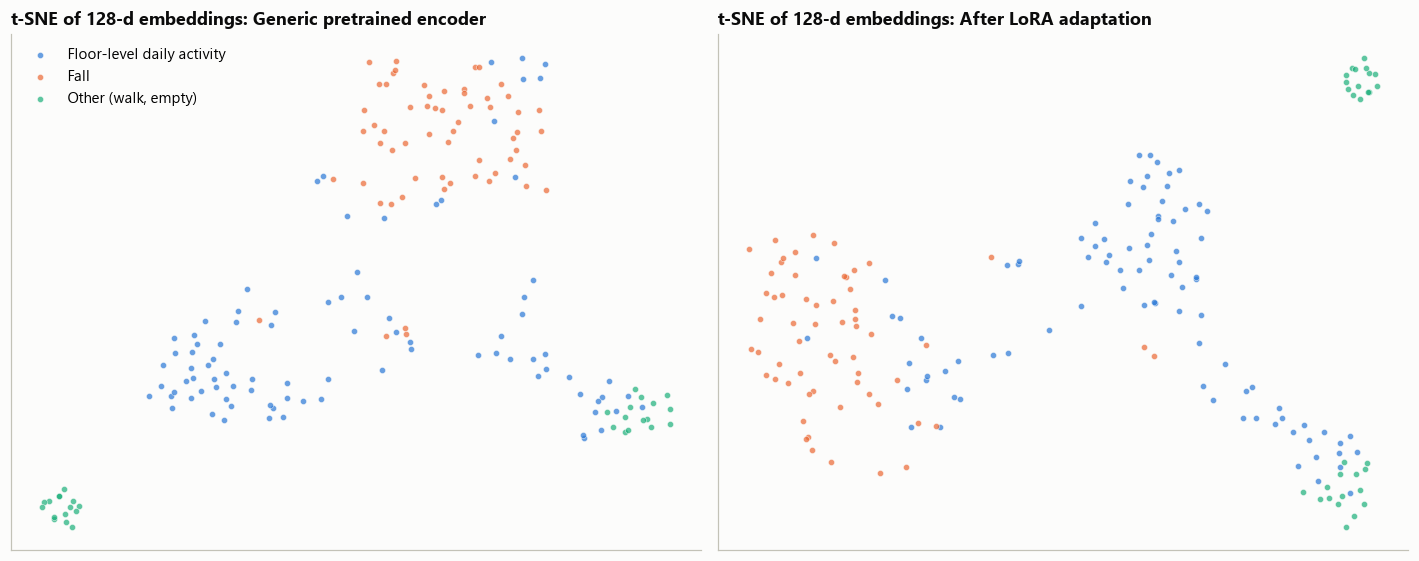

In [26]:
from sklearn.manifold import TSNE

te = split("A")[2]
lora_fold = test_store[(M7, "A->B")]["model"]
Z_generic = embed(pretrained_classifier(), X_lab[te, 1])
Z_adapted = embed(lora_fold.base_model.model, X_lab[te, 1])   # LoRA layers active inside the PEFT wrapper
g = meta.class_name.values[te]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, Z, title in [(axes[0], Z_generic, "Generic pretrained encoder"), (axes[1], Z_adapted, "After LoRA adaptation")]:
    P = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(Z)
    for grp, color in GROUP_COLORS.items():
        m = np.array([group_of(c) == grp for c in g])
        ax.scatter(P[m, 0], P[m, 1], s=16, color=color, alpha=0.7, label=grp, edgecolors="#fcfcfb", linewidths=0.4)
    ax.set(title=f"t-SNE of 128-d embeddings: {title}", xticks=[], yticks=[])
axes[0].legend(loc="best")
plt.tight_layout(); save("15_tsne_embeddings"); plt.show()

## 10. Final adapter, INT8 export and deployment artefact

The deployed adapter is trained on **both layouts** (subjects 1–17). Subjects 18–20 are kept for threshold
calibration. The validation metrics below are therefore *seen-room, unseen-people* numbers and are higher
than the unseen-room results in §7. They are reported only to compare FP32 with INT8. We then merge LoRA into the encoder ($W' = W + \frac{\alpha}{r}BA$), export to ONNX, quantise
weights to INT8 and check that INT8 agrees with FP32. Latency is measured on this laptop's CPU (1 thread).
The ESP32-S3 latency must be measured on hardware (ESP-DL / TFLite-Micro conversion is the next step).

In [27]:
from kubaho.export import export_onnx, quantize_int8, onnx_predict_proba, benchmark_ms

f_tr = np.where(meta.subject <= 17)[0]; f_va = np.where(meta.subject >= 18)[0]
final = lora_model(4)
h = fit(final, X_lab[f_tr], y_lab[f_tr], X_lab[f_va], y_lab[f_va], len(CLASSES),
        TrainConfig(epochs=25, lr=2e-3, seed=SEED), run_name="M7_final_adapter")
p_va = predict_proba(final, X_lab[f_va])
final_thr = calibrate_threshold(y_lab[f_va], p_va[:, FALL])
print(f"final adapter: {h['epochs_run']} epochs, val macro-F1 {h['best_val_macro_f1']:.3f}, threshold {final_thr:.3f}")

final.save_pretrained(MODELS / "kubaho_lora_adapter")           # adapter only (OTA payload)
merged = final.merge_and_unload()
fp32_path = export_onnx(merged, MODELS / "kubaho_lora_fp32.onnx")
int8_path = quantize_int8(fp32_path, MODELS / "kubaho_lora_int8.onnx")

Xv = X_lab[f_va, 1]
p32, p8 = onnx_predict_proba(fp32_path, Xv), onnx_predict_proba(int8_path, Xv)
adapter_file = next((MODELS / "kubaho_lora_adapter").glob("adapter_model.*"))
export_rows = []
for label, path, p in [("FP32", fp32_path, p32), ("INT8", int8_path, p8)]:
    m = evaluate(y_lab[f_va], p, final_thr)
    export_rows.append({"model": label, "file size (KB)": path.stat().st_size / 1024, "CPU latency (ms, median)": benchmark_ms(path),
                        "macro-F1": m["macro_f1"], "fall F1": m["fall_f1"], "fall sensitivity": m["fall_sensitivity"]})
export_df = pd.DataFrame(export_rows)
print(f"INT8 vs FP32 argmax agreement: {(p32.argmax(1) == p8.argmax(1)).mean():.1%}")
print(f"adapter file {adapter_file.name}: {adapter_file.stat().st_size/1024:.1f} KB (includes the 8-class head)")
export_df.round(3)

final adapter: 17 epochs, val macro-F1 0.787, threshold 0.337


INT8 vs FP32 argmax agreement: 98.8%
adapter file adapter_model.safetensors: 23.6 KB (includes the 8-class head)


,model,file size (KB),"CPU latency (ms, median)",macro-F1,fall F1,fall sensitivity
0,FP32,1181.234,0.887,0.787,0.921,0.95
1,INT8,377.539,1.471,0.787,0.921,0.95


In [28]:
card = {
    "version": "kubaho-lora-r4-v0.1",
    "created": time.strftime("%Y-%m-%d"),
    "classes": CLASSES,
    "threshold": round(float(final_thr), 4),
    "input": {"raw_fs": FS, "model_fs": TARGET_FS, "window_s": 2.0, "subcarriers": 52,
              "preprocessing": "interpolate lost packets, Hampel(5, 3σ), Butterworth band-pass 0.2-20 Hz, decimate to 50 Hz"},
    "architecture": {"encoder": "Conv1d stem + 4 transformer blocks (d=128, 4 heads), mean-pooled 128-d embedding",
                     "adapter": "LoRA r=4, alpha=8 on attention q and v", "head": "Linear 128->8",
                     "encoder_params": int(enc_params), "lora_params": int(lp4)},
    "evaluation": {
        "protocol": "leave-one-layout-out with unseen subjects, mean of 2 folds",
        "data": "SYNTHETIC Kubaho-Lab stand-in - preliminary, not validated on real CSI",
        "M7": {k: round(float(v), 4) for k, v in summary.loc[M7, cols].items()},
        "M0_threshold": {k: round(float(v), 4) for k, v in summary.loc["M0 Threshold (RuView-style)", cols].dropna().items()},
    },
    "export": {r["model"]: {"size_kb": round(r["file size (KB)"], 1), "cpu_latency_ms": round(r["CPU latency (ms, median)"], 3)}
               for r in export_rows},
    "files": {"onnx_int8": int8_path.name, "onnx_fp32": fp32_path.name, "adapter": "kubaho_lora_adapter/"},
}
(MODELS / "model_card.json").write_text(json.dumps(card, indent=2))
print(json.dumps(card["evaluation"]["M7"], indent=2))

{
  "accuracy": 0.4931,
  "macro_precision": 0.4479,
  "macro_recall": 0.4698,
  "macro_f1": 0.4213,
  "fall_precision": 0.768,
  "fall_sensitivity": 0.8833,
  "fall_f1": 0.8159,
  "specificity_floor_level": 0.8028,
  "specificity_all_non_fall": 0.8521,
  "false_alarms": 13.0
}


## 11. Summary and next steps

**What this notebook demonstrates (on synthetic data):**
- A complete, reproducible pipeline from raw CSI to a deployable INT8 model: quality phase, features,
  eight compared models, calibrated alert threshold, statistical test, ONNX export and model card.
- The generic threshold detector (M0) fires on many floor-level activities (RQ1, RQ3). This is the false-alarm
  problem the proposal predicts.
- A LoRA adapter that trains under 2% of the encoder's parameters (RQ2) is compared with full fine-tuning
  and the generic baselines in the results table and the success-criteria table above.

**Next steps:**
1. Collect the Kubaho-Lab dataset (20 volunteers, 2 layouts) with the labelling app and swap it in for the
   synthetic generator in `kubaho.data`.
2. Replace the stand-in encoder with the RuView pretrained encoder weights and repeat the benchmark.
3. Add leave-one-subject-out cross-validation on the real data.
4. Convert the merged INT8 model for the ESP32-S3 (ESP-DL / TFLite-Micro) and measure on-device latency
   against the 200 ms budget.
5. Run the 6-week, 8-household pilot. Measure false alarms per household per week and fall-to-SMS time
   (already logged by the API).